# Milestone 3A — Verify the shared PyTorch data loaders

**Objective:** load the existing frozen Pakistani and Stanford Cars manifests with one reusable PyTorch `Dataset`, without reshuffling or modifying any images or split assignments.

- **Pakistan:** 2,610 train, 463 val, 751 test; 48 classes.
- **Stanford Cars:** 6,893 train, 1,214 val, 8,041 test; 196 classes (37 excluded after overlap review).
- Both Xception and ConvNeXt-Tiny will use these exact assignments. The transforms in this notebook are **only for a quick data-loading smoke test**. We will configure training augmentation and model-specific pretrained normalization in Milestone 3B before training.

Run from VS Code using your existing project environment. No GPU is required.

## 1. Find the repository root and import our reusable loader

In [2]:
import sys
print(sys.executable)
print(sys.version)

/Users/bata/Documents/vehicle-make-model-recognition/.venv/bin/python
3.13.2 (v3.13.2:4f8bb3947cf, Feb  4 2025, 11:51:10) [Clang 15.0.0 (clang-1500.3.9.4)]


In [3]:
%pip install torch torchvision timm pyyaml

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
import torchvision
import timm
import yaml

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)

print("MPS available:", torch.backends.mps.is_available())

PyTorch: 2.15.0
Torchvision: 0.29.2
timm: 1.0.30
MPS available: True


In [13]:
from pathlib import Path
import yaml

# Locate the project root
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load shared experiment configuration
config_path = ROOT / "configs" / "experiments.yaml"

assert config_path.exists(), f"Config not found: {config_path}"

with open(config_path, "r") as f:
    cfg = yaml.safe_load(f)

print("Configuration loaded successfully!")
print("Project:", cfg["project_name"])
print("Random seed:", cfg["random_seed"])
print("Image size:", cfg["data_pipeline"]["input_size"])

Configuration loaded successfully!
Project: vehicle-make-model-recognition
Random seed: 42
Image size: [224, 224]


In [14]:
print(cfg["datasets"].keys())

dict_keys(['pakistan', 'verified_split_counts', 'manifest_sha256', 'stanford_cars'])


In [5]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "configs/experiments.yaml").is_file() and (folder / "splits/pakistan/final_manifest.csv").is_file():
            return folder
    raise FileNotFoundError("Repository root not found. Open notebook from within the repository.")

ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT / "src"))

from vehicle_data import VehicleManifestDataset, inspect_manifest
print("Repo:", ROOT)

Repo: /Users/bata/Documents/vehicle-make-model-recognition


## 2. Re-check the frozen manifests and all image paths

`inspect_manifest()` validates the 0-based class mappings, checks all three splits contain all expected classes, and checks every active image path exists. For Stanford, the module also compares the manifest SHA-256 to the frozen verification summary. It **never** creates new splits.

In [6]:
expected = {
    "pakistan": {"train": 2610, "val": 463, "test": 751, "excluded_test_overlap": 23},
    "stanford_cars": {"train": 6893, "val": 1214, "test": 8041, "excluded": 37},
}

for dataset_name in expected:
    info = inspect_manifest(ROOT, dataset_name, check_files=True)
    print(f"\n{dataset_name}:")
    print("  Class count:", info["class_count"])
    print("  Split counts:", info["counts"])
    print("  Manifest SHA-256:", info["manifest_sha256"])
    for split_name, n in expected[dataset_name].items():
        assert info["counts"].get(split_name, 0) == n, (dataset_name, split_name, info["counts"])
print("\nPASS: both frozen manifests match the expected counts and all active files exist.")


pakistan:
  Class count: 48
  Split counts: {'excluded_test_overlap': 23, 'test': 751, 'train': 2610, 'val': 463}
  Manifest SHA-256: 11ebb90a7a4530a2707f4d086131f93f4b3c91cae013bc6add0bc2417bff0f32

stanford_cars:
  Class count: 196
  Split counts: {'train': 6893, 'val': 1214, 'excluded': 37, 'test': 8041}
  Manifest SHA-256: 968552b26c93eb1e163edc99f92e0bc722d710a547d5f290a362ae26224c0ed2

PASS: both frozen manifests match the expected counts and all active files exist.


## 3. Simple *evaluation-style* transform for a smoke test

All images are converted to RGB by `VehicleManifestDataset`. `Resize(256)` scales the shorter side to 256 pixels; `CenterCrop(224)` extracts a consistent central 224×224 square; `ToTensor()` maps pixel values into `[0,1]` and rearranges shape to `[channels, height, width]`.

**Important:** This is **not** the final pretrained model input. In Milestone 3B we will add the correct normalization for each pretrained checkpoint and implement the fixed shared training augmentation specified in `configs/experiments.yaml`.

In [7]:
import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader

smoke_transform = transforms.Compose([
    transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
])

print("Torch:", torch.__version__)
print("Smoke transform:", smoke_transform)

Torch: 2.15.0
Smoke transform: Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
)


## 4. Load a small batch from every split of both datasets

We set `num_workers=0` for easier first-run debugging on your Mac. When training in Colab, we will use the configured worker count (currently 2) and set the DataLoader random seed. The exact image assignments stay unchanged regardless of batch size or shuffling.

In [25]:
datasets_by_name = {}
for dataset_name in ("pakistan", "stanford_cars"):
    datasets_by_name[dataset_name] = {}
    for split_name in ("train", "val", "test"):
        dataset = VehicleManifestDataset(ROOT, dataset_name, split_name, transform=smoke_transform)
        datasets_by_name[dataset_name][split_name] = dataset
        loader = DataLoader(dataset, batch_size=4, shuffle=False, num_workers=0)
        print("Loader created:",len(loader.dataset),"images")
        images, labels = next(iter(loader))
        assert images.shape == (4, 3, 224, 224)
        assert labels.dtype == torch.int64
        print(f"{dataset_name:13} {split_name:5} n={len(dataset):5} images={tuple(images.shape)} labels={labels.tolist()}")
print("\nPASS: both datasets produce valid PyTorch image tensors and integer labels.")

Loader created: 2610 images
pakistan      train n= 2610 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]
Loader created: 463 images
pakistan      val   n=  463 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]
Loader created: 751 images
pakistan      test  n=  751 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]
Loader created: 6893 images
stanford_cars train n= 6893 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]
Loader created: 1214 images
stanford_cars val   n= 1214 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]
Loader created: 8041 images
stanford_cars test  n= 8041 images=(4, 3, 224, 224) labels=[0, 0, 0, 0]

PASS: both datasets produce valid PyTorch image tensors and integer labels.


## 5. Show one batch so we can inspect the inputs visually

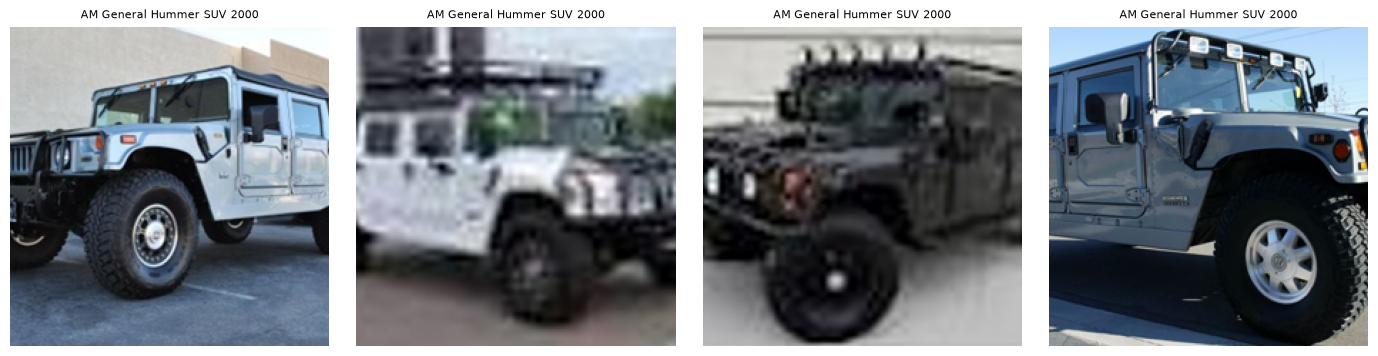

In [9]:
import matplotlib.pyplot as plt

chosen_name = "stanford_cars"   # Change to "pakistan" to inspect the other dataset.
chosen = datasets_by_name[chosen_name]["train"]
images, labels = next(iter(DataLoader(chosen, batch_size=4, shuffle=False, num_workers=0)))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, image, label in zip(axes, images, labels):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(chosen.classes[int(label)], fontsize=8, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Completion criteria

Milestone 3A passes when both manifest audits report the expected counts, every active image exists, both data loaders output `(batch, 3, 224, 224)` tensors, and the displayed labels match the pictured vehicles in the small visual check.

**Next:** Milestone 3B — instantiate `legacy_xception.tf_in1k` and `convnext_tiny.fb_in1k` via `timm`, read their pretrained normalization settings, and implement the common training/validation transformations and two-stage transfer-learning procedure. No accuracy or timing measurements should be entered in the experiment log until actual training runs are completed.

In [15]:
from pathlib import Path
import pandas as pd
import hashlib

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

expected = {
    "pakistan": {
        "train": 2610,
        "val": 463,
        "test": 751,
        "excluded": 23,
    },
    "stanford_cars": {
        "train": 6893,
        "val": 1214,
        "test": 8041,
        "excluded": 37,
    },
}

for name, counts in expected.items():
    path = (
        ROOT
        / cfg["datasets"][name]["split_manifest_dir"]
        / "final_manifest.csv"
    )

    df = pd.read_csv(path)
    actual = df["split"].value_counts()

    for split in ("train", "val", "test"):
        assert actual.get(split, 0) == counts[split]

    assert len(df) == sum(counts.values())

    print(f"{name}: split counts PASS")

pakistan: split counts PASS
stanford_cars: split counts PASS


In [16]:
import hashlib

expected_hashes = {
    "pakistan": "11ebb90a7a4530a2707f4d086131f93f4b3c91cae013bc6add0bc2417bff0f32",
    "stanford_cars": "968552b26c93eb1e163edc99f92e0bc722d710a547d5f290a362ae26224c0ed2",
}

for name, expected in expected_hashes.items():
    path = (
        ROOT
        / cfg["datasets"][name]["split_manifest_dir"]
        / "final_manifest.csv"
    )

    actual = hashlib.sha256(path.read_bytes()).hexdigest()

    assert actual == expected, f"{name}: HASH MISMATCH"
    print(f"{name}: manifest hash PASS")

pakistan: manifest hash PASS
stanford_cars: manifest hash PASS


In [21]:
from torch.utils.data import DataLoader

# Take a snapshot of notebook variables
variables = globals().copy()

found_loaders = {}

for name, obj in variables.items():

    if isinstance(obj, DataLoader):
        found_loaders[name] = obj

    elif isinstance(obj, dict):
        # Snapshot dictionary contents before iterating
        for key, value in list(obj.items()):

            if isinstance(value, DataLoader):
                found_loaders[f"{name}[{key!r}]"] = value

            elif isinstance(value, dict):
                for key2, nested in list(value.items()):
                    if isinstance(nested, DataLoader):
                        found_loaders[
                            f"{name}[{key!r}][{key2!r}]"
                        ] = nested

# Display discovered DataLoaders
for name, loader in found_loaders.items():
    print(f"{name}: {len(loader.dataset)} images")

print("\nTotal DataLoaders found:", len(found_loaders))

loader: 8041 images
found_loaders['loader']: 8041 images
found_loaders["found_loaders['loader']"]: 8041 images
obj['loader']: 8041 images
obj["found_loaders['loader']"]: 8041 images
value: 8041 images

Total DataLoaders found: 6


In [23]:
import torch

images, labels = next(iter(loader))

print("Dataset size:", len(loader.dataset))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())

assert len(loader.dataset) == 8041
assert images.shape[1:] == (3, 224, 224)
assert images.shape[0] == labels.shape[0]
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert torch.isfinite(images).all()
assert ((labels >= 0) & (labels < 196)).all()

print("Stanford Cars batch: PASS")

Dataset size: 8041
Image batch: torch.Size([4, 3, 224, 224])
Label batch: torch.Size([4])
Image dtype: torch.float32
Label dtype: torch.int64
Minimum label: 0
Maximum label: 0
Stanford Cars batch: PASS


In [24]:
image1, label1 = loader.dataset[0]
image2, label2 = loader.dataset[0]

assert torch.equal(image1, image2)
assert label1 == label2

print("Evaluation preprocessing: PASS")

Evaluation preprocessing: PASS


In [26]:
print("Actual loader batch size:", loader.batch_size)
print("Planned training batch size:", cfg["training"]["batch_size"])
print("Planned evaluation batch size:", cfg["training"]["eval_batch_size"])

Actual loader batch size: 4
Planned training batch size: 16
Planned evaluation batch size: 16
